# California Housing Prices — Exploratory Data Analysis

This notebook performs an exploratory data analysis (EDA) of the California Housing Prices dataset.

The goal of this analysis is to understand the structure, quality, distribution, and relationships within the dataset before building a machine learning model.

## Dataset

The dataset was obtained from Kaggle:

[California Housing Prices — Kaggle](https://www.kaggle.com/datasets/camnugent/california-housing-prices)

This dataset contains information about housing districts in California based on data from the 1990 U.S. Census.

## Objectives

- Understand the structure of the dataset
- Inspect data types and basic statistics
- Identify missing values and duplicate records
- Analyze feature distributions
- Detect potential outliers
- Explore correlations between features and the target variable
- Investigate relationships between important features and house prices
- Identify useful insights for the modeling stage

## 1. Import Libraries

We import the libraries required for data manipulation, numerical analysis, and visualization.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

## 2. Load Dataset

We load the dataset into a pandas DataFrame for further analysis.

In [12]:
df = pd.read_csv("D:/Python developer/house-price-prediction-linear-regression/data/housing.csv")

## 3. Initial Data Inspection

Before performing detailed analysis, we inspect the basic structure and contents of the dataset.

In [13]:
df.shape

(20640, 10)

In [14]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [16]:
df.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [17]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

## 4. Data Types

We inspect the data types of each feature to determine how the variables should be handled during preprocessing and modeling.

In [18]:
df.dtypes

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object

In [19]:
df.select_dtypes(include="number").columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value'],
      dtype='object')

In [20]:
df.select_dtypes(include="object").columns

Index(['ocean_proximity'], dtype='object')

## 5. Missing Values

Missing values can affect data analysis and machine learning models.

We identify the number and percentage of missing values in each feature.

In [21]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [22]:
missing_percentage = df.isnull().mean() * 100

missing_percentage.sort_values(ascending=False)

total_bedrooms        1.002907
longitude             0.000000
latitude              0.000000
housing_median_age    0.000000
total_rooms           0.000000
population            0.000000
households            0.000000
median_income         0.000000
median_house_value    0.000000
ocean_proximity       0.000000
dtype: float64

## 6. Duplicate Records

We check whether the dataset contains duplicate rows.

In [23]:
df.duplicated().sum()

np.int64(0)

In [24]:
df[df.duplicated()]

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity


## 7. Descriptive Statistics

Descriptive statistics provide an overview of the numerical features, including their count, mean, standard deviation, minimum, maximum, and quartiles.

In [25]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


## 8. Numerical Feature Distributions

We visualize the distributions of numerical features to understand their range, spread, skewness, and potential unusual values.

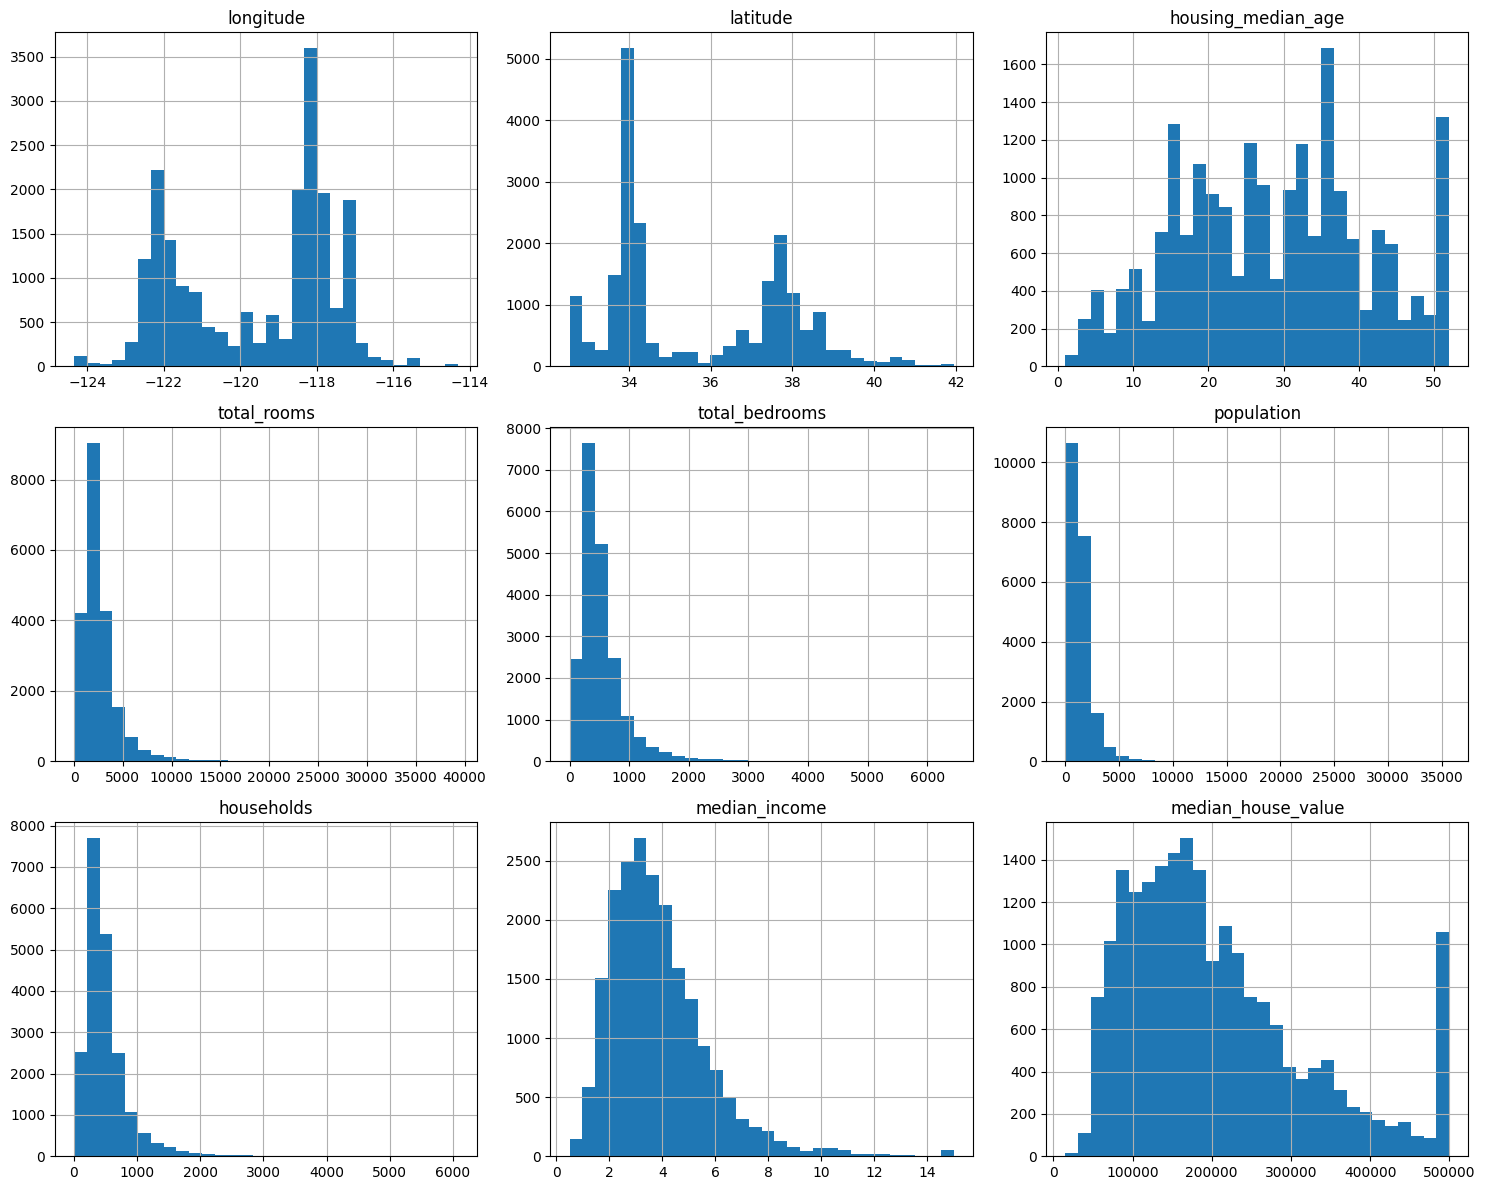

In [26]:
numerical_features = df.select_dtypes(include=np.number).columns

df[numerical_features].hist(
    figsize=(15, 12),
    bins=30
)

plt.tight_layout()
plt.show()

## 9. Target Variable Distribution

The target variable for this project is `median_house_value`.

We examine its distribution to understand the range and overall shape of house prices.

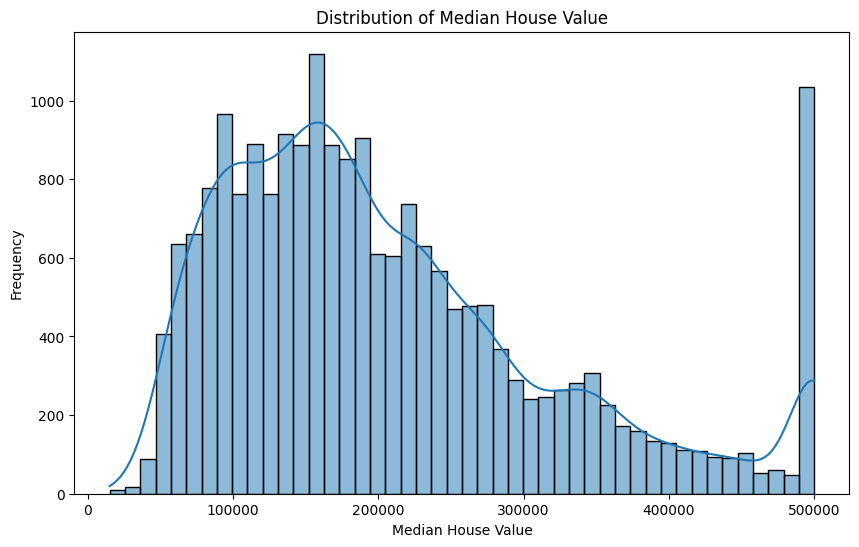

In [27]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="median_house_value",
    kde=True
)

plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

plt.show()

## 10. Outlier Detection

Boxplots are used to identify potential outliers in numerical features.

An outlier is not necessarily an incorrect observation. Potential outliers should be investigated before deciding whether they should be removed or transformed.

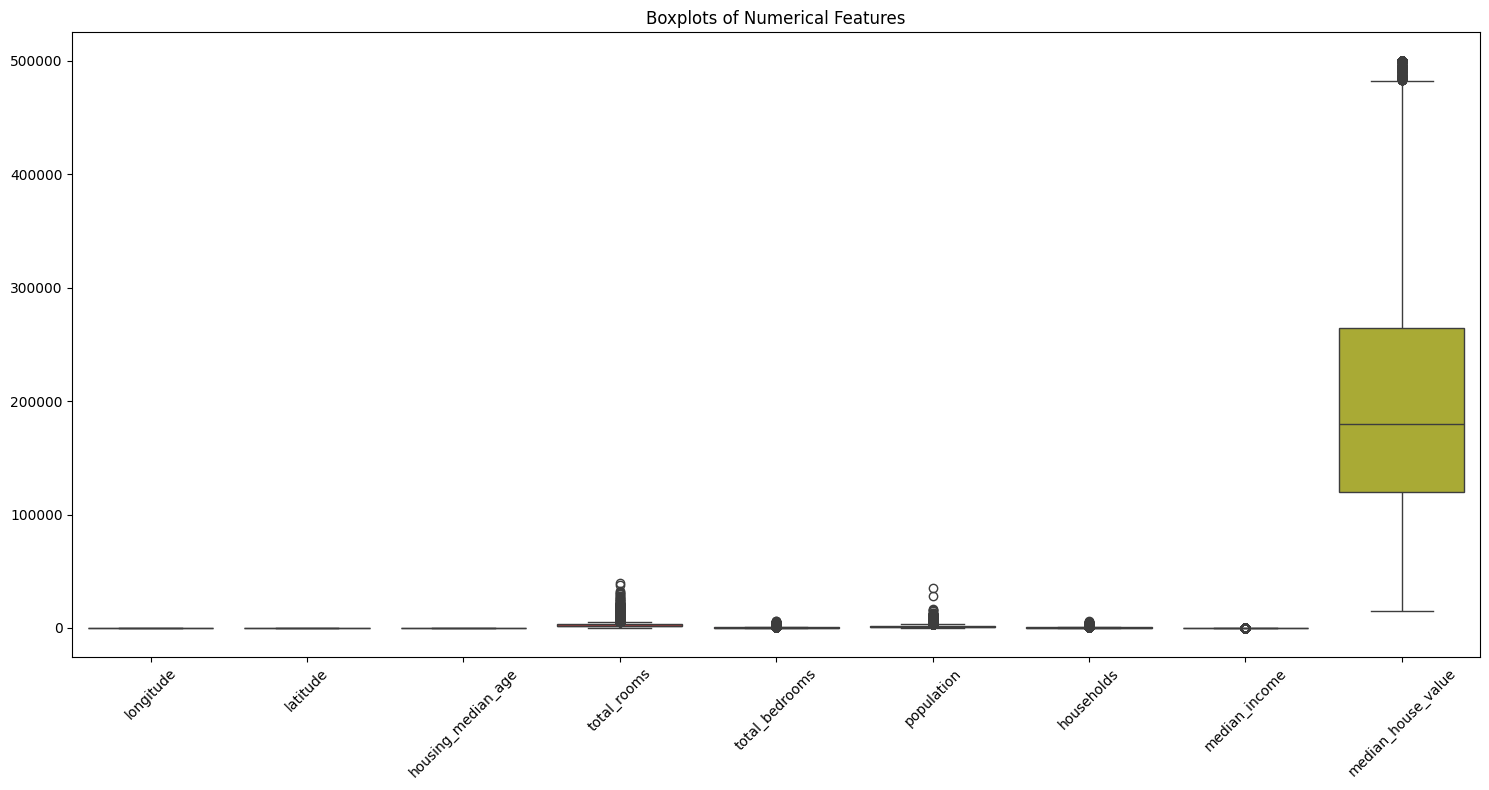

In [28]:
plt.figure(figsize=(15, 8))

sns.boxplot(
    data=df[numerical_features]
)

plt.xticks(rotation=45)
plt.title("Boxplots of Numerical Features")

plt.tight_layout()
plt.show()

## 11. Correlation Analysis

We examine the linear correlation between numerical features.

Correlation can help identify relationships between features and the target variable.

Correlation does not imply causation.

In [29]:
correlation_matrix = df[numerical_features].corr()

correlation_matrix

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


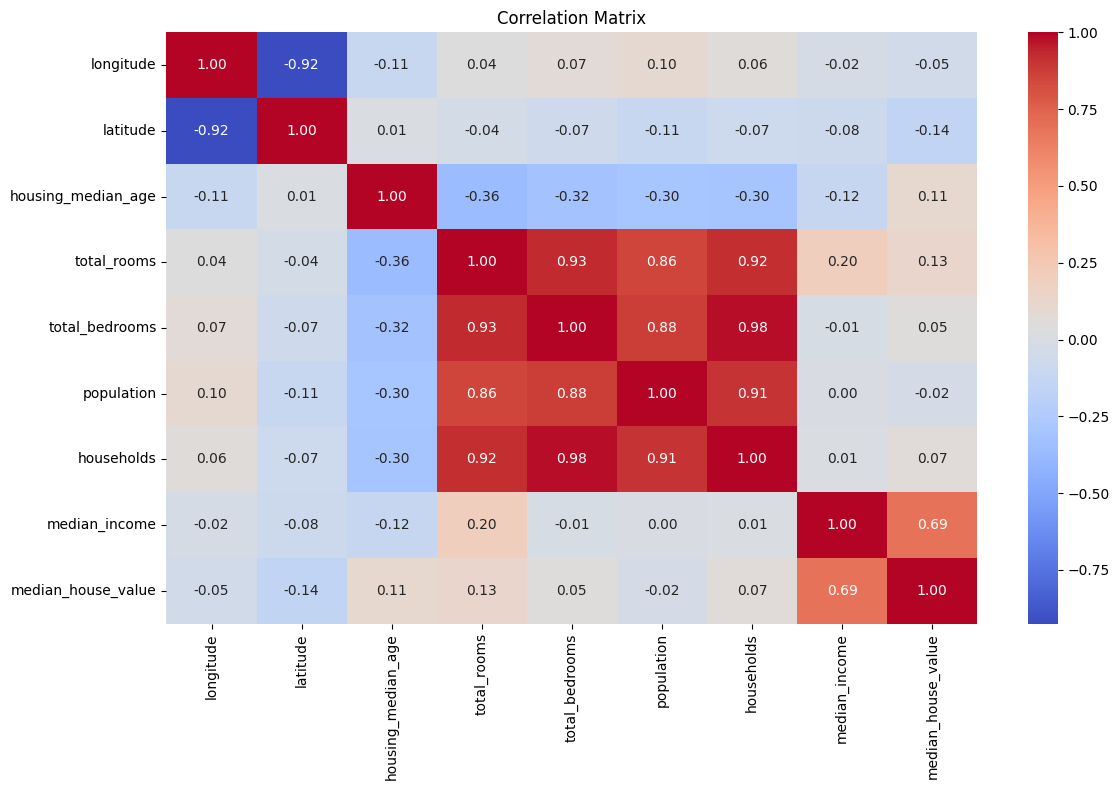

In [30]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

### Correlation with Target

We examine the correlation of each numerical feature with `median_house_value` to identify features that have stronger linear relationships with the target.

In [31]:
target_correlation = (
    correlation_matrix["median_house_value"]
    .sort_values(ascending=False)
)

target_correlation

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

## 12. Feature vs Target Analysis

We visualize the relationship between selected features and the target variable.

This helps us understand whether the relationships appear linear, nonlinear, weak, or strong.

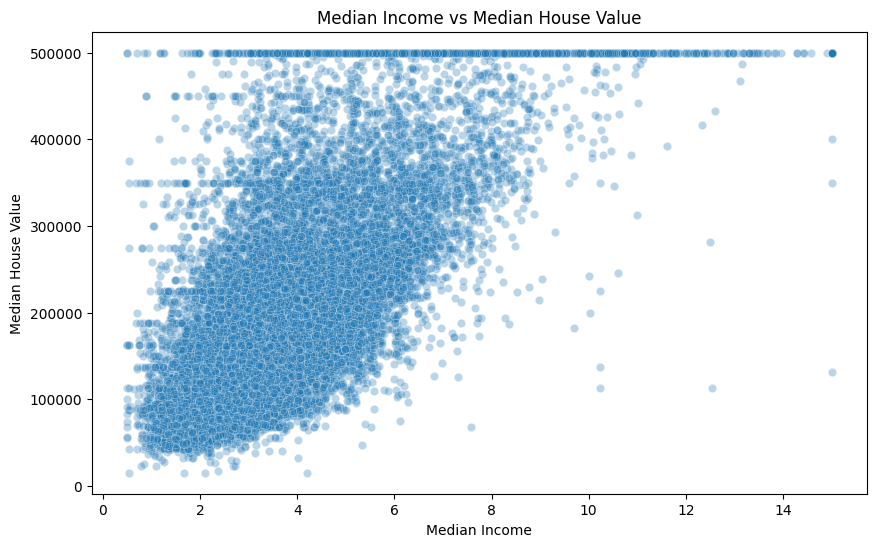

In [32]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="median_income",
    y="median_house_value",
    alpha=0.3
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()

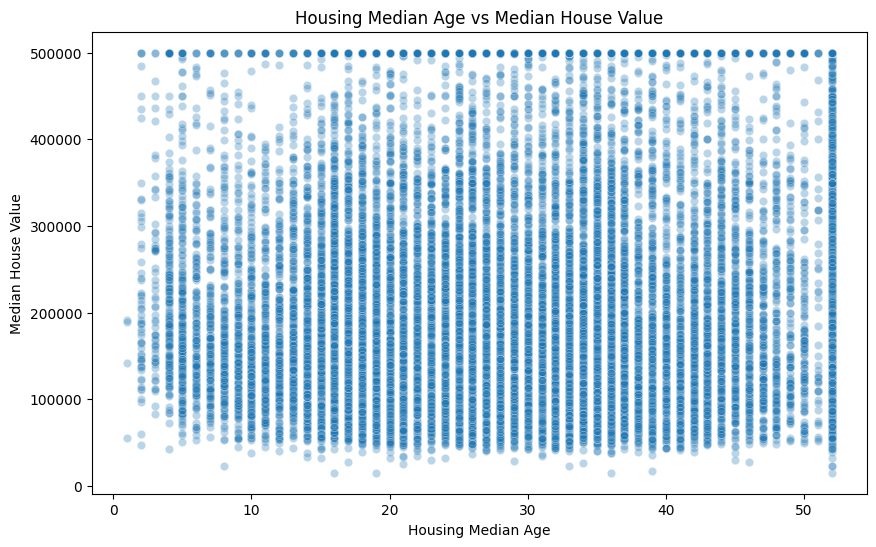

In [33]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="housing_median_age",
    y="median_house_value",
    alpha=0.3
)

plt.title("Housing Median Age vs Median House Value")
plt.xlabel("Housing Median Age")
plt.ylabel("Median House Value")

plt.show()

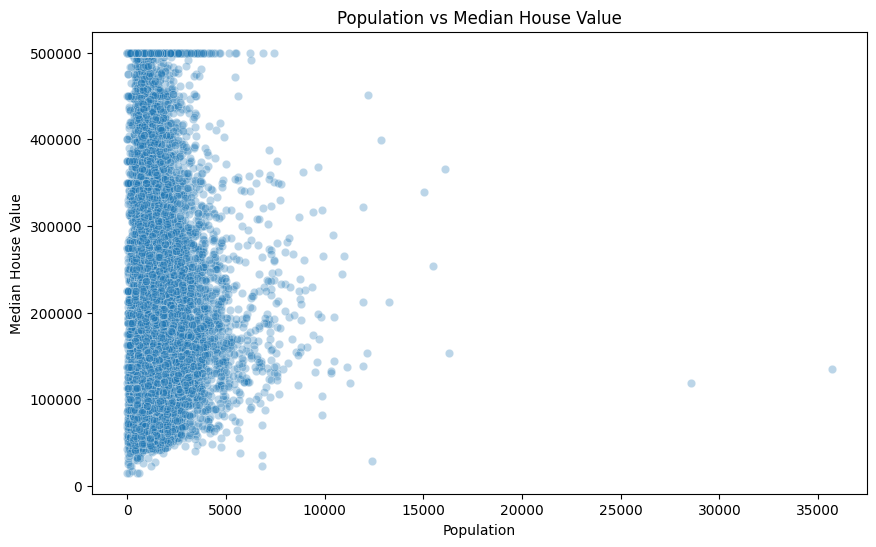

In [34]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="population",
    y="median_house_value",
    alpha=0.3
)

plt.title("Population vs Median House Value")
plt.xlabel("Population")
plt.ylabel("Median House Value")

plt.show()

## 13. EDA Findings

### Dataset Structure
- The dataset contains multiple numerical features describing housing districts in California.
- `median_house_value` is used as the target variable.

### Data Quality
- Missing values were identified and should be handled during preprocessing.
- Duplicate records were checked.

### Feature Distributions
- Several numerical features have skewed distributions.
- Some features contain potential outliers that should be investigated before modeling.

### Correlation
- `median_income` shows a relatively strong positive relationship with `median_house_value`.
- Other features show weaker linear relationships with the target.

### Feature vs Target
- The relationship between `median_income` and `median_house_value` appears to be particularly important.
- Some feature-target relationships do not appear to be strictly linear.

### Modeling Considerations
- Missing values need to be handled before model training.
- Numerical features may require preprocessing depending on the selected model.
- Potential outliers should be investigated rather than automatically removed.
- Feature relationships should be considered when selecting and evaluating regression models.

## 14. Modeling Considerations

Based on the EDA, the following considerations should be addressed before model training:

1. Handle missing values appropriately.
2. Review potential outliers.
3. Select relevant features.
4. Apply appropriate preprocessing to numerical features.
5. Split the dataset into training and testing sets.
6. Evaluate the regression model using appropriate metrics such as MAE, MSE, and RMSE.